In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# From Data to Predictions: Understanding Linear Regression, Noise, Outliers, and Overfitting

## 1. Introduction

Linear regression is a mathematical method used to model the
relationship between variables and make predictions.

It is widely used in statistics, economics, business analytics,
and machine learning.

However, regression models do not always produce reliable predictions.
Noise, outliers, and excessive model complexity can affect their
accuracy and ability to generalize to new data.

## 2. Research Question

How do noise, outliers, and model complexity affect the accuracy
and reliability of regression models?

## 3. Project Objectives

- Explain the mathematical foundations of linear regression.
- Implement regression models using Python.
- Investigate how noise affects model accuracy.
- Examine the influence of outliers.
- Compare models of different polynomial degrees.
- Evaluate model performance using mathematical metrics.
- Visualize and interpret the experimental results.

## 4. Methodology

We will generate controlled datasets, implement regression models,
conduct experiments, evaluate their predictions, and interpret
the results using mathematical reasoning.

## 5. Initial Dataset and Visualization

Before constructing a regression model, we need a dataset containing observed values.

In this project, we use a small dataset with two variables:

- **\(x\)** represents the input variable.
- **\(y\)** represents the observed output variable.

The dataset contains five observations:

$$
x = [1, 2, 3, 4, 5]
$$

$$
y = [3, 4, 5, 4, 6]
$$

We use NumPy arrays to store the values and perform mathematical calculations efficiently.

### 5.1 Visualizing the Observations

A scatter plot allows us to examine the relationship between the input and output variables before fitting a regression model.

Each point represents one observation from the dataset. By visualizing the points, we can look for a general trend and determine whether a linear model might be appropriate.

This initial visualization provides a reference for comparing the observed data with the regression line constructed in the following steps.

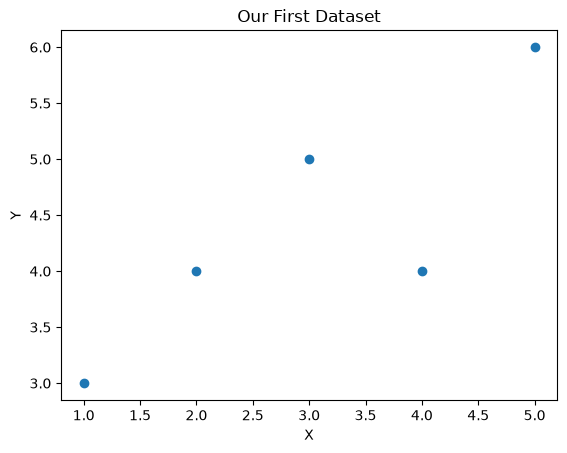

In [2]:
#Input values
x = np.array([1, 2, 3, 4, 5])

#Output values
y = np.array([3, 4, 5, 4, 6])

#Visualize the observations
plt.scatter(x, y)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Our First Dataset")

plt.show()

### 5.2 Calculating the Means

The arithmetic mean represents the average value of a dataset. It is calculated by dividing the sum of all observations by the number of observations.

The mean of the input variable is:

$$
\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i
$$

The mean of the output variable is:

$$
\bar{y}=\frac{1}{n}\sum_{i=1}^{n}y_i
$$

For our dataset, there are five observations, so \(n=5\).

For the input variable:

$$
\bar{x}=\frac{1+2+3+4+5}{5}=3
$$

For the output variable:

$$
\bar{y}=\frac{3+4+5+4+6}{5}=4.4
$$

These means are important because they are used to calculate the slope and intercept of the linear regression line.

In [3]:
#Calculating the means
x_mean = np.mean(x)
y_mean = np.mean(y)

print(f"Mean of x: {x_mean}")
print(f"Mean of y: {y_mean}")

Mean of x: 3.0
Mean of y: 4.4


### 5.3 Deviations from the Means

A deviation measures the difference between an observation and the mean of its variable.

For each observation, we calculate the deviation of the input variable:

$$
x_i-\bar{x}
$$

and the deviation of the output variable:

$$
y_i-\bar{y}
$$

For our dataset, the means are:

$$
\bar{x}=3,\qquad \bar{y}=4.4
$$

For example, the first observation is \(x_1=1\) and \(y_1=3\). Its deviations are:

$$
x_1-\bar{x}=1-3=-2
$$

$$
y_1-\bar{y}=3-4.4=-1.4
$$

A negative deviation means that the observation is below its mean, while a positive deviation means that it is above its mean.

These deviations help us measure how the input and output variables vary together. They are essential for calculating the slope of the least-squares regression line.

### Why Does the Least-Squares Method Work?

Linear regression finds a line that describes the relationship between the input values and the observed output values.

For each observation, the residual is the difference between the observed value and the value predicted by the line:

$$
e_i = y_i - \hat{y}_i
$$

The least-squares method chooses the slope and intercept that minimize the sum of squared residuals:

$$
SSE = \sum_{i=1}^{n}(y_i - \hat{y}_i)^2
$$

Squaring the residuals prevents positive and negative errors from cancelling each other out and gives larger errors more influence.

For a simple linear regression model with an intercept, the slope and intercept can be calculated using the following formulas:

$$
m = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}{\sum_{i=1}^{n}(x_i-\bar{x})^2}
$$

$$
b = \bar{y} - m\bar{x}
$$

These formulas allow us to calculate the best-fitting straight line without relying on a machine-learning library to perform the regression for us.

### 5.4 Calculating the Slope

The slope measures how much the predicted output changes, on average, for a one-unit increase in the input variable.

For a simple linear regression model, the slope is calculated using the least-squares formula:

$$
m=\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}{\sum_{i=1}^{n}(x_i-\bar{x})^2}
$$

The formula consists of two parts.

**Numerator**

$$
\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})
$$

The numerator measures how the deviations of the input and output variables vary together. Multiplying the deviations gives positive products when both deviations have the same sign and negative products when their signs differ.

**Denominator**

$$
\sum_{i=1}^{n}(x_i-\bar{x})^2
$$

The denominator measures the total squared deviation of the input variable from its mean. Squaring the deviations makes them non-negative.

For our dataset, the numerator is:

$$
2.8+0.4+0-0.4+3.2=6
$$

The denominator is:

$$
(-2)^2+(-1)^2+0^2+1^2+2^2=10
$$

Therefore, the slope is:

$$
m=\frac{6}{10}=0.6
$$

A positive slope indicates an upward trend. In our model, the predicted output increases by \(0.6\) units for each one-unit increase in the input variable.

In [4]:
#Calculating the deviations from the means
x_deviations = x - x_mean
y_deviations = y - y_mean

#Calculating the numerator and denominator
numerator = np.sum(x_deviations * y_deviations)
denominator = np.sum(x_deviations ** 2)

#Calculating the slope
m = numerator / denominator

print(f"Numerator: {numerator}")
print(f"Denominator: {denominator}")
print(f"Slope: {m}")

Numerator: 6.0
Denominator: 10.0
Slope: 0.6


### 5.5 Calculating the Intercept

The intercept determines where the regression line crosses the vertical axis. It represents the predicted value of \(y\) when \(x=0\).

The intercept is calculated using the means and the slope:

$$
b=\bar{y}-m\bar{x}
$$

For our dataset, we have:

$$
\bar{x}=3,\qquad \bar{y}=4.4,\qquad m=0.6
$$

Substituting these values into the formula gives:

$$
b=4.4-(0.6\times3)
$$

$$
b=4.4-1.8=2.6
$$

Therefore, the intercept is $b=2.6$

The intercept ensures that the regression line passes through the point formed by the means of the two variables, $(\bar{x},\bar{y})$.

Together, the slope and intercept define our linear regression model.

### 5.6 Constructing the Regression Equation

Simple linear regression uses the equation:

$$
\hat{y} = mx + b
$$

where:

- $\hat{y}$ represents the predicted output value.
- $m$ represents the slope of the regression line.
- $x$ represents the input value.
- $b$ represents the intercept.

From our calculations, we obtained:

$$
m = 0.6, \qquad b = 2.6
$$

Substituting these values into the general equation gives:

$$
\hat{y} = 0.6x + 2.6
$$

This equation allows us to predict an output value for any given input $x$.

For example, when $x = 4$:

$$
\hat{y} = 0.6(4) + 2.6 = 5.0
$$

The predicted value is $5.0$, while the observed value in our dataset is $4$. The difference between these values is called a **residual**, which we will examine later in the project.

This regression equation serves as our baseline model for investigating how noise, outliers, and model complexity affect prediction accuracy.

In [5]:
#Calculating the intercept
b = y_mean - m * x_mean

print(f"Slope: {m}")
print(f"Intercept: {b:.1f}")
print(f"Regression equation: y = {m}x + {b:.1f}")

Slope: 0.6
Intercept: 2.6
Regression equation: y = 0.6x + 2.6


### 5.7 Visualizing the Regression Line

After calculating the slope and intercept, we can visualize our linear regression model by plotting the observed data alongside the regression line.

The regression equation is:

$$
\hat{y} = 0.6x + 2.6
$$

For each input value $x$, the model calculates a predicted output value $\hat{y}$ using this equation.

In the plot:

- **Observed Data:** The actual output values in our dataset.
- **Regression Line:** The output values predicted by our model.

Comparing the observed values with the predicted values helps us understand how closely the model represents the relationship between the input and output variables.

The regression line captures the general upward trend in our dataset, although it does not pass through every observed point. These differences will help us investigate residuals, noise, and outliers in later sections.

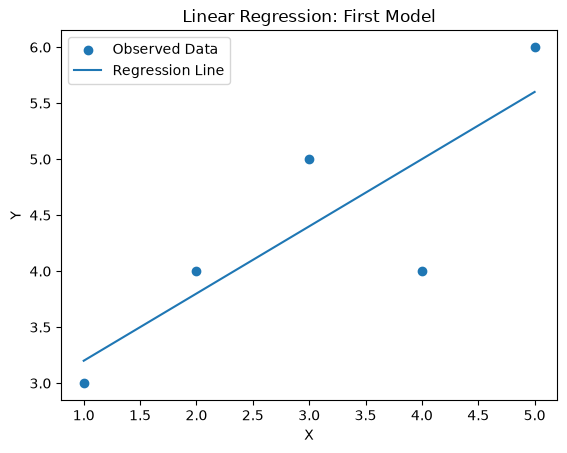

In [6]:
#Visualizing
#Calculate predicted y values
y_pred = m * x + b

#Plot the original observations
plt.scatter(x, y, label = "Observed Data")

#Plot the regression line
plt.plot(x, y_pred, label = "Regression Line")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Linear Regression: First Model")
plt.legend()
plt.show()


### 5.8 Calculating Residuals

A residual measures the difference between an observed output value and the value predicted by our regression model.

The residual for observation $i$ is defined as:

$$
e_i = y_i - \hat{y}_i
$$

where:

- $e_i$ is the residual.
- $y_i$ is the observed output value.
- $\hat{y}_i$ is the predicted output value.

A positive residual means that the observed value is greater than the predicted value. A negative residual means that the observed value is smaller than the predicted value.

For our dataset, the regression model is:

$$
\hat{y} = 0.6x + 2.6
$$

Consider the observation where $x=4$ and the observed output is $y=4$.

The predicted output is:

$$
\hat{y} = 0.6(4) + 2.6 = 5.0
$$

Therefore, the residual is:

$$
e = 4 - 5.0 = -1.0
$$

The negative residual indicates that the model overestimated the observed output by $1.0$ for this observation.

Residuals help us evaluate the errors made by a regression model and will be important when we investigate noise, outliers, and prediction accuracy.

In [7]:
residuals = y - y_pred

print(f"Observed values: {y}")
print(f"Predicted values: {y_pred}")
print(f"Residuals: {residuals}")

Observed values: [3 4 5 4 6]
Predicted values: [3.2 3.8 4.4 5.  5.6]
Residuals: [-0.2  0.2  0.6 -1.   0.4]


### 5.9 Interpreting the Residuals

The calculated residuals show the differences between the observed output values and the predictions made by our regression model.

Our residuals are:

$$
[-0.2,\ 0.2,\ 0.6,\ -1.0,\ 0.4]
$$

Each residual corresponds to one observation in our dataset.

- A positive residual means the model underestimated the observed value.
- A negative residual means the model overestimated the observed value.
- A residual close to zero indicates that the prediction is close to the observed value.

For example, when $x=4$, the observed value is $y=4$, while the predicted value is $\hat{y}=5.0$. The residual is therefore:

$$
e = 4 - 5.0 = -1.0
$$

This is the largest absolute residual in our current dataset, meaning that this observation has the largest prediction error in absolute terms.

Residuals help us assess how well a model fits the observed data. However, a single residual does not determine whether a model is reliable overall. We will later compare models using quantitative evaluation metrics and controlled experiments.

### 5.9.1 Visualizing the Residuals

The residual plot shows each prediction error at its input value. Points above zero are positive residuals, which mean the model predicted too low. Points below zero are negative residuals, which mean it predicted too high.

This plot contains only five observations, so it is useful for illustrating residuals but not for identifying a reliable statistical pattern.

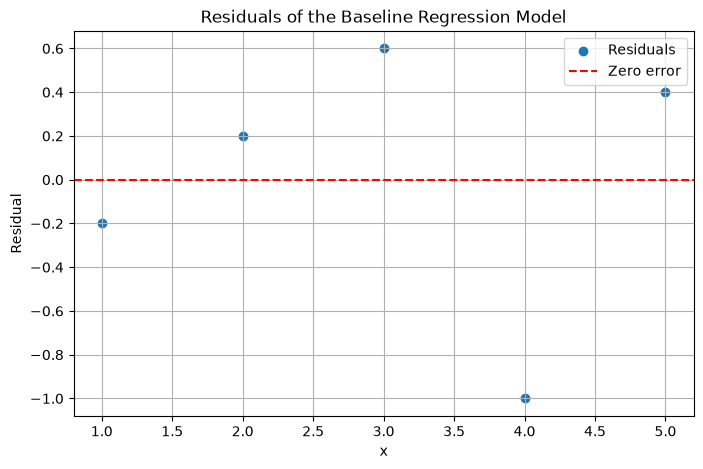

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(x, residuals, label="Residuals")
plt.axhline(0, color="red", linestyle="--", label="Zero error")

plt.xlabel("x")
plt.ylabel("Residual")
plt.title("Residuals of the Baseline Regression Model")
plt.legend()
plt.grid(True)
plt.show()

### 5.10 Mean Absolute Error (MAE)

The residuals show the prediction error for each individual observation. To summarize these errors in a single value, we can calculate the Mean Absolute Error (MAE).

MAE is the arithmetic mean of the absolute residuals. Absolute values ensure that positive and negative errors do not cancel each other out.

The formula is:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
$$

where:

- $n$ is the number of observations.
- $y_i$ is the observed output.
- $\hat{y}_i$ is the predicted output.

For our dataset, the residuals are:

$$
[-0.2,\ 0.2,\ 0.6,\ -1.0,\ 0.4]
$$

Taking their absolute values gives:

$$
[0.2,\ 0.2,\ 0.6,\ 1.0,\ 0.4]
$$

The MAE is the average of these absolute errors:

$$
MAE = \frac{0.2+0.2+0.6+1.0+0.4}{5}=0.48
$$

Therefore, the model's Mean Absolute Error is $0.48$.

A lower MAE generally indicates more accurate predictions when comparing models on the same dataset and target scale. However, MAE alone does not tell us whether the model captures the underlying relationship or generalizes well to new data.

In [9]:
absolute_residuals = np.abs(residuals)

mae = np.mean(absolute_residuals)

print(f"Absolute Residuals: {absolute_residuals}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")

Absolute Residuals: [0.2 0.2 0.6 1.  0.4]
Mean Absolute Error (MAE): 0.48


### 5.11 Mean Squared Error (MSE)

The Mean Squared Error (MSE) measures the average of the squared differences between observed and predicted values.

Unlike MAE, MSE squares each residual before calculating the average. This makes larger prediction errors contribute disproportionately to the final result.

The formula is:

$$
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

For our dataset, the residuals are:

$$
[-0.2,\ 0.2,\ 0.6,\ -1.0,\ 0.4]
$$

Squaring each residual gives:

$$
[0.04,\ 0.04,\ 0.36,\ 1.00,\ 0.16]
$$

Therefore, the Mean Squared Error is:

$$
MSE = \frac{0.04+0.04+0.36+1.00+0.16}{5}
$$

$$
MSE = \frac{1.60}{5}=0.32
$$

Our model has an MSE of $0.32$.

A lower MSE generally indicates smaller squared prediction errors when comparing models on the same dataset and target scale. Because errors are squared, MSE is particularly sensitive to large errors, making it useful when substantial prediction mistakes should be penalized more heavily.

In [10]:
squared_residuals = residuals ** 2

mse = np.mean(squared_residuals)

print(f"Squared Residuals: {squared_residuals}")
print(f"Mean Squared Error (MSE): {mse:.2f}")

Squared Residuals: [0.04 0.04 0.36 1.   0.16]
Mean Squared Error (MSE): 0.32


### 5.12 Root Mean Squared Error (RMSE)

The Root Mean Squared Error (RMSE) is the square root of the Mean Squared Error.

The formula is:

$$
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
$$

Because RMSE takes the square root of MSE, it expresses prediction error in the same units as the original output variable.

From our previous calculation:

$$
MSE = 0.32
$$

Therefore:

$$
RMSE = \sqrt{0.32} \approx 0.566
$$

Our model has an RMSE of approximately $0.566$.

Like MSE, RMSE penalizes larger errors more heavily than MAE. However, RMSE is often easier to interpret because it uses the same units as the observed output values.

When comparing models on the same dataset and target scale, lower RMSE generally indicates better predictive accuracy. RMSE should still be interpreted alongside other metrics and the context of the problem.

In [11]:
rmse = np.sqrt(mse)

print(f"Root Mean Squared Error (RMSE): {rmse:.3f}")

Root Mean Squared Error (RMSE): 0.566


### 5.13 Comparing the Evaluation Metrics

We have evaluated our linear regression model using three metrics: Mean Absolute Error (MAE), Mean Squared Error (MSE), and Root Mean Squared Error (RMSE).

Our results are:

| Metric | Value | Interpretation |
|---|---:|---|
| MAE | 0.48 | Average absolute prediction error |
| MSE | 0.32 | Average squared prediction error |
| RMSE | 0.566 | Error measure in the original output units |

Each metric describes prediction error from a different perspective.

- **MAE** measures the average magnitude of the errors without considering their direction.
- **MSE** squares the errors, giving larger errors a greater influence on the result.
- **RMSE** takes the square root of MSE, returning the measure to the original units of the output variable.

These values provide a baseline for evaluating our regression model. Later, we can compare them with the results obtained after introducing noise and outliers.

An important limitation is that these metrics are calculated on the same observations used to fit the model. They describe the model's fit to this small dataset, but they do not independently establish how well it will predict unseen data.

## 6. Investigating the Effect of Noise

Noise refers to random variation in observed data that is not explained by the underlying relationship between variables.

In real-world datasets, measurements may contain noise due to measurement errors, unpredictable events, or other factors that influence the observed outcomes.

To investigate its effect on linear regression, we will introduce controlled random noise into the output variable while keeping the input variable unchanged.

The original dataset and regression model will serve as our baseline. We will then compare the model fitted to the noisy data with the original model.

We will examine:

- How noise changes the observed data and fitted regression line.
- How noise affects the estimated slope and intercept.
- How prediction error changes when we evaluate the models.

By changing the amount of noise while keeping the experiment controlled, we can better understand how random variation affects regression model fitting.

For reproducibility, we will use a fixed random seed so that the experiment produces the same noise values each time the notebook is executed.

### 6.1 Generating Random Noise

To simulate random variation, we will generate noise using NumPy's random number generator.

We will use a normal distribution with a mean of zero. This means that the noise is centered around zero, so it does not intentionally increase or decrease all observations.

The noise is controlled by two parameters:

- **Mean ($\mu$):** The center of the noise distribution, set to zero.
- **Standard deviation ($\sigma$):** Controls how spread out the noise values are. A larger standard deviation produces greater variation.

We will begin with a standard deviation of $0.5$ to introduce a modest amount of noise.

A fixed random seed ensures that the generated values remain reproducible when the notebook is rerun.

In [12]:
rng = np.random.default_rng(seed=42)

noise = rng.normal(loc=0, scale=0.5, size=len(y))

print(f"Original y values: {y}")
print(f"Generated noise: {noise}")

Original y values: [3 4 5 4 6]
Generated noise: [ 0.15235854 -0.51999205  0.3752256   0.47028236 -0.97551759]


### 6.2 Creating the Noisy Dataset

We can create a noisy version of the original dataset by adding the generated noise values to the observed output values.

The transformation is defined as:

$$
y_{\text{noisy}} = y + \epsilon
$$

where:

- $y$ represents the original output values.
- $\epsilon$ represents the generated random noise.
- $y_{\text{noisy}}$ represents the output values after noise has been added.

Adding noise changes the observed outputs while keeping the input values unchanged.

We will store the modified outputs in a separate NumPy array rather than overwriting the original $y$ values. This allows us to compare the original and noisy datasets directly.

Because the noise is random and centered around zero, some observations will increase while others will decrease. The amount of variation depends on the chosen standard deviation.

In [13]:
y_noisy = y + noise

print("Original y values:", y)
print("Noisy y values:", y_noisy)

Original y values: [3 4 5 4 6]
Noisy y values: [3.15235854 3.48000795 5.3752256  4.47028236 5.02448241]


### 6.3 Visualizing the Noisy Dataset

A scatter plot allows us to compare the original observations with the observations after noise has been added.

We will plot both datasets using the same input values.

- **Original observations:** The output values before noise was introduced.
- **Noisy observations:** The output values after adding random noise.

Because the input values remain unchanged, the vertical differences between corresponding points represent the added noise.

This visualization helps us see how random variation changes the observed data. However, a visual comparison alone does not establish how much the regression model's predictive accuracy has changed. We will investigate that by fitting a regression model to the noisy dataset and comparing evaluation metrics.

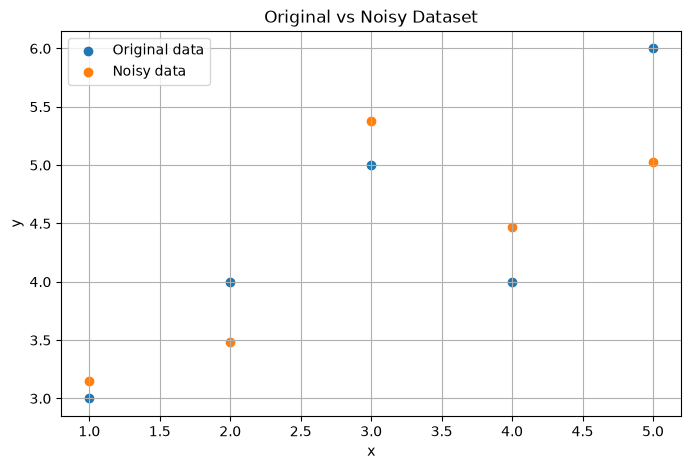

In [14]:
plt.figure(figsize=(8, 5))

plt.scatter(x, y, label="Original data")
plt.scatter(x, y_noisy, label="Noisy data")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Original vs Noisy Dataset")
plt.legend()
plt.grid(True)

plt.show()

### 6.4 Fitting a Regression Model to Noisy Data

After introducing noise, we can fit a new linear regression model to the noisy dataset.

The original model was fitted using the observed output values $y$. The new model will use $y_{\text{noisy}}$ instead.

We calculate the slope and intercept using the same least-squares method as before:

$$
m_{\text{noisy}} =
\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_{\text{noisy},i}-\bar{y}_{\text{noisy}})}
{\sum_{i=1}^{n}(x_i-\bar{x})^2}
$$

$$
b_{\text{noisy}} =
\bar{y}_{\text{noisy}}-m_{\text{noisy}}\bar{x}
$$

The resulting regression equation is:

$$
\hat{y}_{\text{noisy}}=m_{\text{noisy}}x+b_{\text{noisy}}
$$

By comparing the new slope and intercept with the original values, we can investigate how random variation affects the fitted model.

We will use separate variable names to preserve the original model for comparison.

In [15]:
y_noisy_mean = np.mean(y_noisy)

y_noisy_deviations = y_noisy - y_noisy_mean

numerator_noisy = np.sum(x_deviations * y_noisy_deviations)
denominator_noisy = np.sum(x_deviations ** 2)

m_noisy = numerator_noisy / denominator_noisy
b_noisy = y_noisy_mean - m_noisy * x_mean

y_noisy_pred = m_noisy * x + b_noisy

print(f"Noisy slope: {m_noisy:.3f}")
print(f"Noisy intercept: {b_noisy:.3f}")
print(f"Noisy regression equation: y = {m_noisy:.3f}x + {b_noisy:.3f}")

Noisy slope: 0.473
Noisy intercept: 2.880
Noisy regression equation: y = 0.473x + 2.880


### 6.5 Comparing the Original and Noisy Regression Lines

We can compare the original regression model with the model fitted to the noisy dataset by plotting both regression lines alongside the original observations.

The original regression equation is:

$$
\hat{y}=0.6x+2.6
$$

The noisy regression equation is:

$$
\hat{y}_{\text{noisy}}=m_{\text{noisy}}x+b_{\text{noisy}}
$$

Both models use the same input values, but they are fitted to different output values.

By displaying the lines on the same graph, we can visually examine how the added noise changes the estimated slope and intercept.

A difference between the two lines demonstrates that random variation in the observed outputs can affect the fitted regression model. However, a visual difference alone does not establish which model predicts better. We will compare their prediction errors separately.

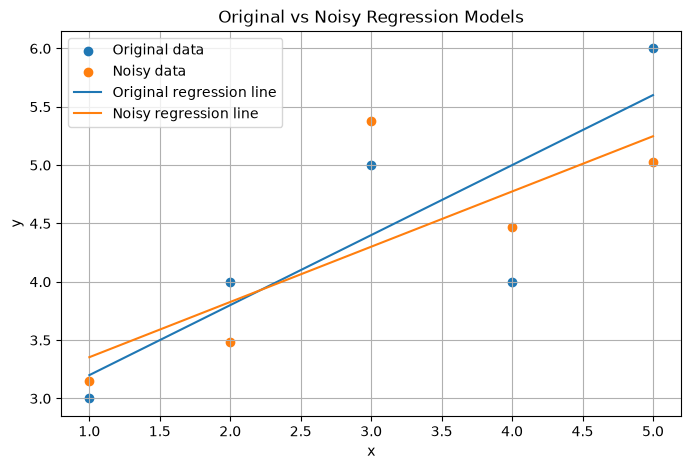

In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(x, y, label="Original data")
plt.scatter(x, y_noisy, label="Noisy data")

plt.plot(x, y_pred, label="Original regression line")
plt.plot(x, y_noisy_pred, label="Noisy regression line")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Original vs Noisy Regression Models")
plt.legend()
plt.grid(True)

plt.show()

### 6.6 Comparing Prediction Errors

To quantify how closely the regression models fit their respective datasets, we will calculate MAE, MSE, and RMSE for both models.

For the original model, the errors are calculated using the original observations:

$$
e_i = y_i - \hat{y}_i
$$

For the noisy model, the errors are calculated using the noisy observations:

$$
e_{\text{noisy},i}=y_{\text{noisy},i}-\hat{y}_{\text{noisy},i}
$$

We will calculate the three evaluation metrics for each model using the same formulas introduced in Section 5.

Comparing these values helps us understand how closely each model fits its own dataset. However, the models are fitted to different observed outputs, so the comparison must be interpreted carefully.

In particular, a lower training error does not necessarily mean a model will perform better on new data. Evaluating generalization requires separate test data or another appropriate validation method.

In [17]:
residuals_noisy = y_noisy - y_noisy_pred

mae_noisy = np.mean(np.abs(residuals_noisy))
mse_noisy = np.mean(residuals_noisy ** 2)
rmse_noisy = np.sqrt(mse_noisy)

print(f"Noisy model MAE: {mae_noisy:.3f}")
print(f"Noisy model MSE: {mse_noisy:.3f}")
print(f"Noisy model RMSE: {rmse_noisy:.3f}")

Noisy model MAE: 0.430
Noisy model MSE: 0.292
Noisy model RMSE: 0.540


### 6.7 Comparing the Evaluation Metrics

We can summarize the evaluation metrics for the original and noisy regression models in a comparison table.

The original model's metrics are:

- MAE = 0.48
- MSE = 0.32
- RMSE ≈ 0.566

The noisy model's metrics were calculated using the residuals between the noisy observations and their predicted values.

This comparison helps us describe how closely each regression line fits its own dataset.

The metrics should be interpreted with care because the models were fitted to different output values. The noisy model's errors measure its fit to the noisy data, while the original model's errors measure its fit to the original data.

These results demonstrate how adding random variation changes the data and the fitted model. To investigate the effect of noise more rigorously, we can repeat the experiment at different noise levels while keeping the underlying dataset and experimental procedure consistent.

Training error alone cannot establish which model generalizes better to unseen data.

In [18]:
comparison = pd.DataFrame({
    "Model": ["Original", "Noisy"],
    "MAE": [mae, mae_noisy],
    "MSE": [mse, mse_noisy],
    "RMSE": [rmse, rmse_noisy]
})

comparison.round(3)

,Model,MAE,MSE,RMSE
0,Original,0.48,0.320,0.566
1,Noisy,0.43,0.292,0.540


### 6.8 Investigating Stronger Noise

The amount of random noise is controlled by its standard deviation, $\sigma$.

A larger standard deviation produces a wider distribution of possible noise values. This generally increases the variation introduced into the observed outputs, although individual random values can still be small.

In the previous experiment, we used:

$$
\sigma = 0.5
$$

In this experiment, we will increase the standard deviation to:

$$
\sigma = 1.5
$$

We will keep the original input values unchanged and use the same underlying output data. We will then fit another regression model to the more heavily perturbed observations.

Comparing the fitted equations and training errors across noise levels will help us investigate how stronger random variation affects the regression model.

We will use a fixed random seed to make the experiment reproducible.

In [19]:
rng_strong = np.random.default_rng(42)

noise_strong = rng_strong.normal(
    loc=0,
    scale=1.5,
    size=len(y)
)

y_strong_noisy = y + noise_strong

print("Original y values:", y)
print("Strong noise:", noise_strong)
print("Strongly noisy y values:", y_strong_noisy)

Original y values: [3 4 5 4 6]
Strong noise: [ 0.45707562 -1.55997616  1.12567679  1.41084707 -2.92655278]
Strongly noisy y values: [3.45707562 2.44002384 6.12567679 5.41084707 3.07344722]


### 6.9 Fitting a Regression Model to Strongly Noisy Data

In this experiment, we fit a linear regression model to the strongly noisy dataset. We calculate the slope and intercept using the same least-squares formulas as before.

By comparing these parameters with the original model, we can investigate how stronger noise affects the fitted regression line.

In [20]:
y_strong_mean = np.mean(y_strong_noisy)
y_strong_deviations = y_strong_noisy - y_strong_mean

numerator_strong = np.sum(x_deviations * y_strong_deviations)
denominator_strong = np.sum(x_deviations ** 2)

m_strong = numerator_strong / denominator_strong
b_strong = y_strong_mean - m_strong * x_mean

y_strong_pred = m_strong * x + b_strong

print(f"Strong-noise slope: {m_strong:.3f}")
print(f"Strong-noise intercept: {b_strong:.3f}")
print(f"Strong-noise regression equation: y = {m_strong:.3f}x + {b_strong:.3f}")

Strong-noise slope: 0.220
Strong-noise intercept: 3.440
Strong-noise regression equation: y = 0.220x + 3.440


### 6.10 Visualizing the Strongly Noisy Regression Model

We now plot the original data, the strongly noisy data, and both regression lines on the same graph.

This visualization helps us observe how stronger noise changes the fitted regression line compared with the original model.

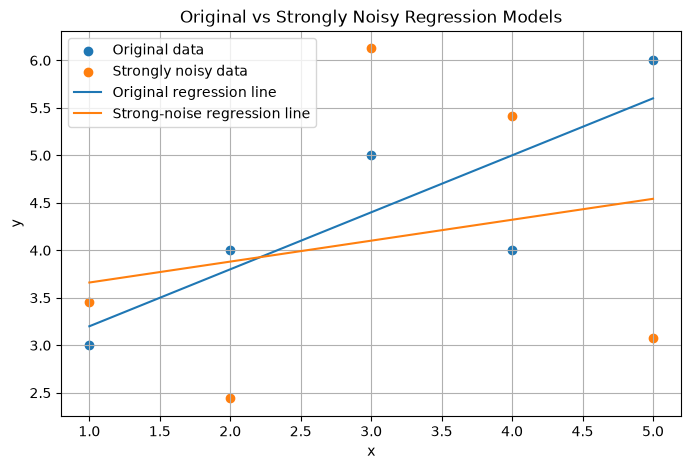

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(x, y, label="Original data")
plt.scatter(x, y_strong_noisy, label="Strongly noisy data")

plt.plot(x, y_pred, label="Original regression line")
plt.plot(x, y_strong_pred, label="Strong-noise regression line")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Original vs Strongly Noisy Regression Models")
plt.legend()
plt.grid(True)
plt.show()

### 6.11 Evaluating the Strongly Noisy Model

We calculate the Mean Absolute Error (MAE), Mean Squared Error (MSE), and Root Mean Squared Error (RMSE) for the strongly noisy model.

These metrics measure how closely the regression line fits the strongly noisy dataset. Since the model is evaluated on the same data used to fit it, these results measure training error rather than performance on unseen data.

In [22]:
residuals_strong = y_strong_noisy - y_strong_pred

mae_strong = np.mean(np.abs(residuals_strong))
mse_strong = np.mean(residuals_strong ** 2)
rmse_strong = np.sqrt(mse_strong)

print(f"Strong-noise model MAE: {mae_strong:.3f}")
print(f"Strong-noise model MSE: {mse_strong:.3f}")
print(f"Strong-noise model RMSE: {rmse_strong:.3f}")

Strong-noise model MAE: 1.245
Strong-noise model MSE: 1.912
Strong-noise model RMSE: 1.383


### 6.12 Comparing the Original, Noisy, and Strongly Noisy Models

We compare the evaluation metrics from all three regression models. This table helps us examine how the errors change as we introduce stronger noise into the dataset.

Each model's metrics describe its fit to its own dataset, so the values should be interpreted as a comparison of training errors rather than a direct comparison of predictive performance on unseen data.

An important limitation is that each model is evaluated against the dataset used to fit it. Therefore, the error metrics cannot establish which model predicts unseen data most accurately. A fair comparison of predictive performance would require evaluating the models on the same independent test dataset.

In [23]:
comparison_all = pd.DataFrame({
    "Model": ["Original", "Noisy (SD = 0.5)", "Strong noise (SD = 1.5)"],
    "Slope": [m, m_noisy, m_strong],
    "Intercept": [b, b_noisy, b_strong],
    "MAE": [mae, mae_noisy, mae_strong],
    "MSE": [mse, mse_noisy, mse_strong],
    "RMSE": [rmse, rmse_noisy, rmse_strong]
})

comparison_all.round(3)

,Model,Slope,Intercept,MAE,MSE,RMSE
0,Original,0.600,2.60,0.480,0.320,0.566
1,Noisy (SD = 0.5),0.473,2.88,0.430,0.292,0.540
2,Strong noise (SD = 1.5),0.220,3.44,1.245,1.912,1.383


### 6.13 Comparing Noise-Fitted Models on a Common Reference Grid

The training metrics above are calculated on different noisy datasets, so they are not a fair comparison of predictive accuracy. Here, we compare each fitted line at the same set of input values. We use the original baseline regression equation, $\\hat{y}=0.6x+2.6$, as a reference trend and calculate each model's deviation from it.

This controlled comparison shows how much the estimated line changes as noise is added. The reference values are generated from the baseline equation; they are not independent real-world observations. Therefore, these metrics measure deviation from the chosen reference trend, not proven accuracy on real unseen data.

In [24]:
x_reference = np.linspace(x.min(), x.max(), 100)
y_reference = m * x_reference + b

reference_models = {
    "Baseline": m * x_reference + b,
    "Noise (SD = 0.5)": m_noisy * x_reference + b_noisy,
    "Noise (SD = 1.5)": m_strong * x_reference + b_strong,
}

reference_comparison = pd.DataFrame([
    {
        "Model": name,
        "MAE from reference": np.mean(np.abs(predictions - y_reference)),
        "RMSE from reference": np.sqrt(np.mean((predictions - y_reference) ** 2)),
    }
    for name, predictions in reference_models.items()
])

reference_comparison.round(3)

,Model,MAE from reference,RMSE from reference
0,Baseline,0.000,0.000
1,Noise (SD = 0.5),0.147,0.178
2,Noise (SD = 1.5),0.442,0.534


The table compares all three fitted lines over the same 100 x-values and against the same baseline trend. A larger deviation means that the fitted line moved farther from the baseline under this particular noise realization. Since the reference is defined from the original five-point fit, this result is a sensitivity illustration; evaluating generalization would require additional observations from a known or independently measured process.

### 6.14 Repeating the Noise Experiment

A single random draw can produce an unusually small or large change in the fitted slope. To see how the result varies across repeated draws, we repeat the experiment 500 times for each noise level, keeping the original five input-output pairs fixed.

We summarize the mean and standard deviation of the fitted slopes, along with the mean absolute change from the baseline slope. The fixed random seed makes the simulation reproducible. This experiment illustrates variation for this small dataset; it does not replace evaluation on additional independent observations.

In [25]:
n_simulations = 500
noise_levels = [0.5, 1.5]
rng_simulation = np.random.default_rng(123)
simulation_results = []

for noise_level in noise_levels:
    simulated_slopes = []

    for _ in range(n_simulations):
        simulated_y = y + rng_simulation.normal(
            loc=0,
            scale=noise_level,
            size=len(y)
        )
        simulated_y_mean = np.mean(simulated_y)
        simulated_slope = np.sum(
            x_deviations * (simulated_y - simulated_y_mean)
        ) / denominator
        simulated_slopes.append(simulated_slope)

    simulation_results.append({
        "Noise SD": noise_level,
        "Mean slope": np.mean(simulated_slopes),
        "Slope SD": np.std(simulated_slopes),
        "Mean absolute slope change": np.mean(
            np.abs(np.array(simulated_slopes) - m)
        ),
    })

noise_simulation_summary = pd.DataFrame(simulation_results)
noise_simulation_summary.round(3)

,Noise SD,Mean slope,Slope SD,Mean absolute slope change
0,0.5,0.597,0.169,0.134
1,1.5,0.603,0.470,0.378


Across repeated draws, a larger noise standard deviation should generally produce more variation in the fitted slope. The exact values depend on the fixed seed and the five input positions. The simulation demonstrates how one small sample can respond to random noise; it does not establish how a model will perform on unseen data.

## 7. Investigating the Effect of Outliers

An outlier is a data point that differs substantially from the general pattern of a dataset. Outliers can strongly influence linear regression because the model attempts to minimize the sum of squared residuals.

In this experiment, we introduce one unusually large value into a separate copy of the original dataset. We then compare the regression model fitted to the original data with the model fitted to the dataset containing the outlier.

We keep the original dataset unchanged so that the effect of the outlier can be studied independently.

In [26]:
y_outlier = y.copy()

y_outlier[-1] = 15

print("Original y values:", y)
print("Dataset with outlier:", y_outlier)

Original y values: [3 4 5 4 6]
Dataset with outlier: [ 3  4  5  4 15]


### 7.1 Fitting a Regression Model with an Outlier

We fit a new linear regression model using the dataset containing the outlier. We use the same least-squares method as in the baseline experiment.

Comparing the new slope and intercept with the original model will show how a single extreme observation can influence the fitted regression line.

In [27]:
y_outlier_mean = np.mean(y_outlier)
y_outlier_deviations = y_outlier - y_outlier_mean

numerator_outlier = np.sum(x_deviations * y_outlier_deviations)
denominator_outlier = np.sum(x_deviations ** 2)

m_outlier = numerator_outlier / denominator_outlier
b_outlier = y_outlier_mean - m_outlier * x_mean

y_outlier_pred = m_outlier * x + b_outlier

print(f"Original slope: {m:.3f}")
print(f"Outlier slope: {m_outlier:.3f}")
print(f"Original intercept: {b:.3f}")
print(f"Outlier intercept: {b_outlier:.3f}")
print(f"Outlier regression equation: y = {m_outlier:.3f}x + {b_outlier:.3f}")

Original slope: 0.600
Outlier slope: 2.400
Original intercept: 2.600
Outlier intercept: -1.000
Outlier regression equation: y = 2.400x + -1.000


### 7.2 Visualizing the Effect of the Outlier

We plot the original data, the dataset containing the outlier, and both regression lines on the same graph.

This visualization allows us to see how the extreme data point influences the slope and position of the fitted regression line.

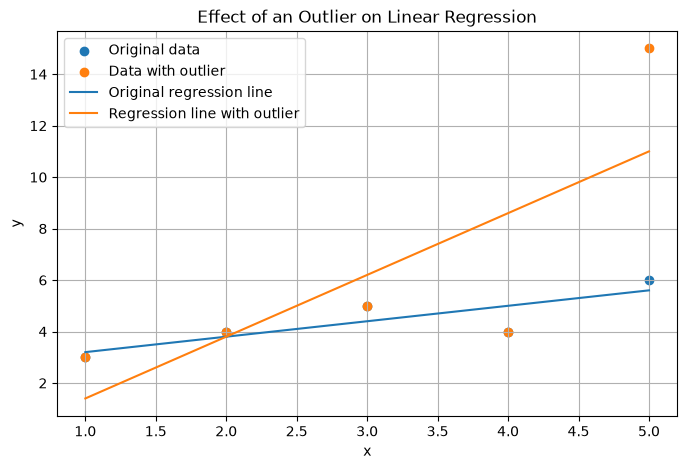

In [28]:
plt.figure(figsize=(8, 5))

plt.scatter(x, y, label="Original data")
plt.scatter(x, y_outlier, label="Data with outlier")

plt.plot(x, y_pred, label="Original regression line")
plt.plot(x, y_outlier_pred, label="Regression line with outlier")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Effect of an Outlier on Linear Regression")
plt.legend()
plt.grid(True)
plt.show()

### 7.3 Evaluating the Model with an Outlier

We calculate MAE, MSE, and RMSE for the regression model fitted to the dataset containing the outlier.

These metrics help us quantify the model's residual errors and investigate how the extreme observation affects the fitted model.

In [29]:
residuals_outlier = y_outlier - y_outlier_pred

mae_outlier = np.mean(np.abs(residuals_outlier))
mse_outlier = np.mean(residuals_outlier ** 2)
rmse_outlier = np.sqrt(mse_outlier)

print(f"Outlier model MAE: {mae_outlier:.3f}")
print(f"Outlier model MSE: {mse_outlier:.3f}")
print(f"Outlier model RMSE: {rmse_outlier:.3f}")

Outlier model MAE: 2.320
Outlier model MSE: 8.240
Outlier model RMSE: 2.871


### 7.4 Comparing the Baseline and Outlier Results

The table below compares the original regression model with the model fitted after changing the final output value to create an outlier. It includes the slope, intercept, and error metrics for each fit.

Each model's MAE and RMSE are calculated on the same observations used to fit that model. The outlier model is evaluated against the modified dataset, while the baseline model is evaluated against the original dataset. These values describe training fit and should not be interpreted as a direct comparison of prediction accuracy.

In [30]:
outlier_comparison = pd.DataFrame({
    "Model": ["Baseline", "With outlier"],
    "Slope": [m, m_outlier],
    "Intercept": [b, b_outlier],
    "MAE": [mae, mae_outlier],
    "RMSE": [rmse, rmse_outlier],
})

outlier_comparison.round(3)

,Model,Slope,Intercept,MAE,RMSE
0,Baseline,0.6,2.6,0.48,0.566
1,With outlier,2.4,-1.0,2.32,2.871


The slope increases from 0.6 to 2.4 after the final output value changes from 6 to 15, showing how strongly this point affects the fitted line. The outlier model's larger training errors also show that the changed dataset is harder for a straight line to fit closely. Since the two models are evaluated against different versions of the data, the error metrics alone do not tell us which model predicts better.

## 8. Understanding Overfitting

Overfitting occurs when a model learns the training data too closely, including random noise and unusual patterns, instead of capturing the underlying relationship.

A more complex model can fit the training data better without necessarily making better predictions on new, unseen data.

In this section, we compare polynomial models of different degrees. A higher-degree polynomial can produce a more flexible curve than a linear model. We will investigate how model complexity affects the fit to our small dataset.

Because our original dataset contains only five observations, this experiment is an illustration of model flexibility rather than definitive evidence of generalization performance.

In [31]:
coefficients_degree1 = np.polyfit(x, y, 1)
coefficients_degree2 = np.polyfit(x, y, 2)
coefficients_degree4 = np.polyfit(x, y, 4)

x_smooth = np.linspace(min(x), max(x), 200)

y_degree1 = np.polyval(coefficients_degree1, x_smooth)
y_degree2 = np.polyval(coefficients_degree2, x_smooth)
y_degree4 = np.polyval(coefficients_degree4, x_smooth)

print("Degree 1: linear model")
print("Degree 2: quadratic model")
print("Degree 4: highly flexible polynomial model")

Degree 1: linear model
Degree 2: quadratic model
Degree 4: highly flexible polynomial model


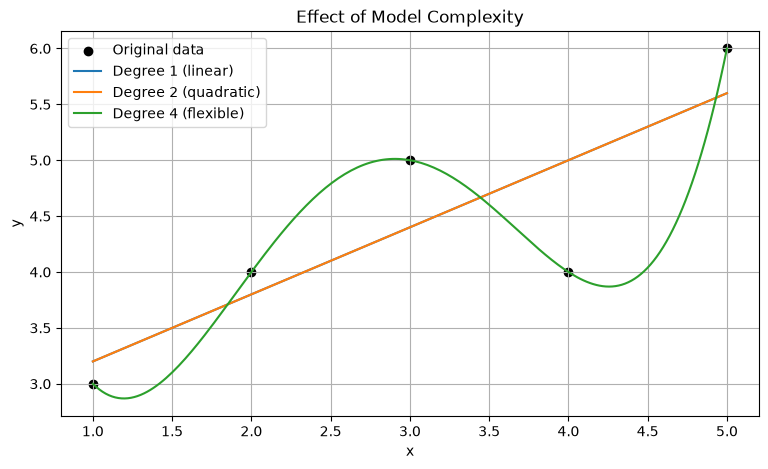

In [32]:
plt.figure(figsize=(9, 5))

plt.scatter(x, y, label="Original data", color="black")

plt.plot(x_smooth, y_degree1, label="Degree 1 (linear)")
plt.plot(x_smooth, y_degree2, label="Degree 2 (quadratic)")
plt.plot(x_smooth, y_degree4, label="Degree 4 (flexible)")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Effect of Model Complexity")
plt.legend()
plt.grid(True)
plt.show()

### 8.1 Comparing Polynomial Training Errors

We can compare how closely each polynomial degree fits the five observations by calculating MAE and RMSE on those same observations. This measures training error for each model.

In [33]:
polynomial_models = {
    1: coefficients_degree1,
    2: coefficients_degree2,
    4: coefficients_degree4,
}

polynomial_results = []

for degree, coefficients in polynomial_models.items():
    y_polynomial_pred = np.polyval(coefficients, x)
    polynomial_residuals = y - y_polynomial_pred
    polynomial_mse = np.mean(polynomial_residuals ** 2)

    polynomial_results.append({
        "Degree": degree,
        "Training MAE": np.mean(np.abs(polynomial_residuals)),
        "Training RMSE": np.sqrt(polynomial_mse),
    })

polynomial_comparison = pd.DataFrame(polynomial_results)
polynomial_comparison.round(3)

,Degree,Training MAE,Training RMSE
0,1,0.48,0.566
1,2,0.48,0.566
2,4,0.00,0.000


The degree-4 model has training errors close to zero because a fourth-degree polynomial can pass through all five observations. This table compares fit to the training data only. It does not show that the degree-4 model will predict new observations more accurately; that would require independent evaluation data.

### 8.2 Interpreting Model Complexity

The visualization demonstrates that increasing model complexity allows a model to fit the training data more closely. The degree-1 model captures the overall linear trend, while the degree-4 model follows every observed data point.

However, a perfect fit to a small training dataset does not guarantee reliable predictions. A highly flexible model may capture random variations rather than the underlying relationship.

This illustrates the trade-off between model simplicity and flexibility. Choosing an appropriate model requires considering not only its training error but also its performance on unseen data.

In this experiment, the degree-4 polynomial has zero training error because it passes through all five observations. However, this result alone does not prove that the model will overfit in practice. To confirm overfitting, we would need to compare training and test errors using additional observations that were not used to fit the models.

## 9. Conclusions

This project investigated how noise, outliers, and model complexity affect linear regression.

The baseline experiment demonstrated how to calculate a regression line using the least-squares method and evaluate its residual errors with MAE, MSE, and RMSE.

The noise experiments showed how adding random variation changes the dataset and the fitted regression model. Increasing the noise level can make the underlying relationship harder to identify, although the exact effect depends on the particular noise values.

The outlier experiment demonstrated that a single extreme observation can substantially change the slope and intercept of a regression line. Because least-squares regression minimizes squared errors, observations with large residuals can have a strong influence on the fitted model.

Finally, the polynomial experiment illustrated how more complex models can fit training data more closely. However, a perfect training fit does not guarantee accurate predictions on unseen data, highlighting the risk of overfitting.

An important limitation of this project is the small dataset, which contains only five observations. The experiments are useful for illustrating mathematical concepts, but they are not sufficient to establish how well these models would generalize to real-world data.

Overall, reliable regression analysis requires more than fitting a model to observed data. It also requires understanding the data, examining unusual observations, selecting an appropriate level of model complexity, and evaluating predictive performance on unseen data.